In [2]:
%pip install numpy pandas matplotlib seaborn scikit-learn mlflow fastapi uvicorn openpyxl

Defaulting to user installation because normal site-packages is not writeable

   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------------- 1/3 [openpyxl]
   ------------- -------------------

In [3]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [4]:
# Create folders for dataset versioning and models

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("data/features", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Project folders created successfully.")

Project folders created successfully.


In [5]:
DATA_PATH = "bank_churn.csv"

# If the file is in another location, use:
# DATA_PATH = r"D:\4-1\MLOps\Lab3\bank_churn.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (6120, 14)


,customer_id,credit_score,geography,gender,age,tenure_years,balance,num_products,has_cr_card,is_active_member,estimated_salary,monthly_transactions,complaints_last_year,churn
0,102094,743.520061,Germany,Female,38.460855,1,83722.026007,2,No,No,29157.083621,16,0,1
1,101612,729.479880,Germany,FEMALE,29.115844,7,68053.038287,1,No,Yes,121774.883439,4,1,0
2,105858,NaN,Germany,Male,33.687474,0,92560.217237,1,No,No,121329.645742,13,0,1
3,104294,758.594734,Spain,Male,39.134293,10,8811.863054,1,Yes,No,150230.538972,12,6,1
4,102571,519.626773,France,FEMALE,42.524934,4,24966.092387,3,Yes,Yes,47438.911368,17,0,0


In [6]:
DATA_PATH = "bank_churn.csv"

# If the file is in another location, use:
# DATA_PATH = r"D:\4-1\MLOps\Lab3\bank_churn.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (6120, 14)


,customer_id,credit_score,geography,gender,age,tenure_years,balance,num_products,has_cr_card,is_active_member,estimated_salary,monthly_transactions,complaints_last_year,churn
0,102094,743.520061,Germany,Female,38.460855,1,83722.026007,2,No,No,29157.083621,16,0,1
1,101612,729.479880,Germany,FEMALE,29.115844,7,68053.038287,1,No,Yes,121774.883439,4,1,0
2,105858,NaN,Germany,Male,33.687474,0,92560.217237,1,No,No,121329.645742,13,0,1
3,104294,758.594734,Spain,Male,39.134293,10,8811.863054,1,Yes,No,150230.538972,12,6,1
4,102571,519.626773,France,FEMALE,42.524934,4,24966.092387,3,Yes,Yes,47438.911368,17,0,0


In [7]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
display(df["churn"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6120 entries, 0 to 6119
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           6120 non-null   int64  
 1   credit_score          5938 non-null   float64
 2   geography             5997 non-null   object 
 3   gender                6120 non-null   object 
 4   age                   6120 non-null   float64
 5   tenure_years          6120 non-null   int64  
 6   balance               5814 non-null   float64
 7   num_products          6120 non-null   int64  
 8   has_cr_card           5937 non-null   object 
 9   is_active_member      6120 non-null   object 
 10  estimated_salary      5878 non-null   float64
 11  monthly_transactions  6120 non-null   int64  
 12  complaints_last_year  6120 non-null   int64  
 13  churn                 6120 non-null   int64  
dtypes: float64(4), int64(6), object(4)
memory usage: 66

customer_id               0
credit_score            182
geography               123
gender                    0
age                       0
tenure_years              0
balance                 306
num_products              0
has_cr_card             183
is_active_member          0
estimated_salary        242
monthly_transactions      0
complaints_last_year      0
churn                     0
dtype: int64


Duplicate Rows: 118

Target Distribution:


churn
0    4760
1    1360
Name: count, dtype: int64

In [8]:
# Remove duplicate rows
df = df.drop_duplicates()

# Standardize gender values
df["gender"] = df["gender"].str.strip().str.lower()

# Standardize binary columns
binary_columns = ["has_cr_card", "is_active_member"]

for col in binary_columns:
    df[col] = df[col].str.strip().str.lower()

print("After cleaning:", df.shape)
display(df.head())

After cleaning: (6002, 14)


,customer_id,credit_score,geography,gender,age,tenure_years,balance,num_products,has_cr_card,is_active_member,estimated_salary,monthly_transactions,complaints_last_year,churn
0,102094,743.520061,Germany,female,38.460855,1,83722.026007,2,no,no,29157.083621,16,0,1
1,101612,729.479880,Germany,female,29.115844,7,68053.038287,1,no,yes,121774.883439,4,1,0
2,105858,NaN,Germany,male,33.687474,0,92560.217237,1,no,no,121329.645742,13,0,1
3,104294,758.594734,Spain,male,39.134293,10,8811.863054,1,yes,no,150230.538972,12,6,1
4,102571,519.626773,France,female,42.524934,4,24966.092387,3,yes,yes,47438.911368,17,0,0


In [9]:
raw_path = "data/raw/bank_churn_raw.csv"

df.to_csv(raw_path, index=False)

print("Raw dataset saved at:", raw_path)

Raw dataset saved at: data/raw/bank_churn_raw.csv


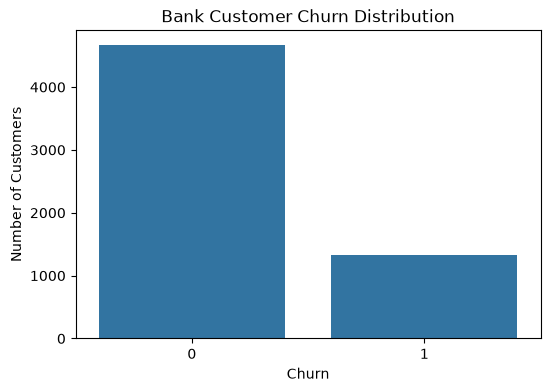

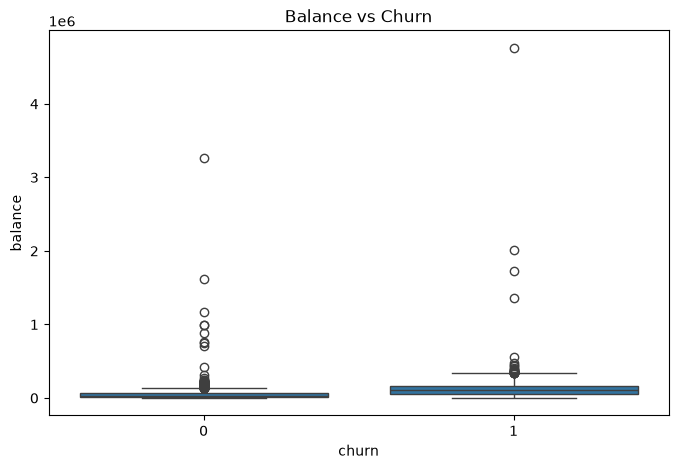

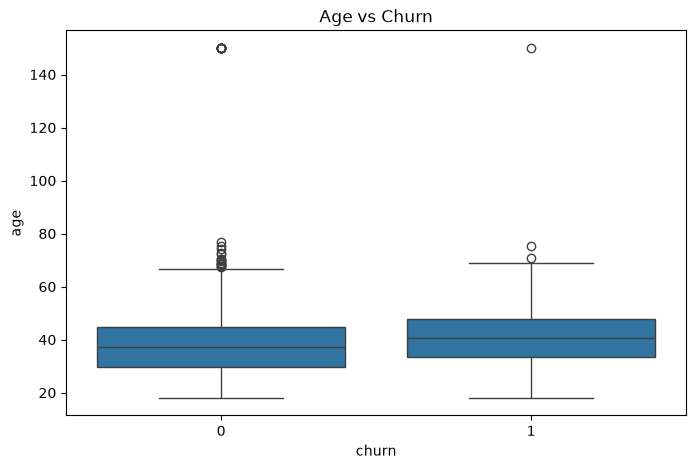

In [10]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="churn")

plt.title("Bank Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="churn", y="balance")

plt.title("Balance vs Churn")
plt.show()
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="churn", y="age")

plt.title("Age vs Churn")
plt.show()

In [11]:
TARGET = "churn"

X = df.drop(columns=[TARGET, "customer_id"])
y = df[TARGET]

print("Features:")
print(X.columns.tolist())

print("\nTarget:", TARGET)

Features:
['credit_score', 'geography', 'gender', 'age', 'tenure_years', 'balance', 'num_products', 'has_cr_card', 'is_active_member', 'estimated_salary', 'monthly_transactions', 'complaints_last_year']

Target: churn


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (4801, 12)
Testing Shape: (1201, 12)


In [13]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['credit_score', 'age', 'tenure_years', 'balance', 'num_products', 'estimated_salary', 'monthly_transactions', 'complaints_last_year']

Categorical Features:
['geography', 'gender', 'has_cr_card', 'is_active_member']


In [14]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [15]:
processed_df = df.copy()

processed_path = "data/processed/bank_churn_processed.csv"

processed_df.to_csv(processed_path, index=False)

print("Processed dataset saved at:", processed_path)

Processed dataset saved at: data/processed/bank_churn_processed.csv


In [16]:
def feature_engineering(data):
    data = data.copy()

    # Avoid division by zero
    data["balance_per_product"] = (
        data["balance"] /
        data["num_products"].replace(0, np.nan)
    )

    data["salary_to_balance_ratio"] = (
        data["estimated_salary"] /
        data["balance"].replace(0, np.nan)
    )

    data["complaints_per_transaction"] = (
        data["complaints_last_year"] /
        data["monthly_transactions"].replace(0, np.nan)
    )

    data["is_senior_customer"] = (
        data["age"] >= 50
    ).astype(int)

    data["is_high_value_customer"] = (
        data["balance"] > data["balance"].median()
    ).astype(int)

    return data

In [17]:
df_features = feature_engineering(df)

print("Feature-Engineered Shape:", df_features.shape)

display(df_features.head())

Feature-Engineered Shape: (6002, 19)


,customer_id,credit_score,geography,gender,age,tenure_years,balance,num_products,has_cr_card,is_active_member,estimated_salary,monthly_transactions,complaints_last_year,churn,balance_per_product,salary_to_balance_ratio,complaints_per_transaction,is_senior_customer,is_high_value_customer
0,102094,743.520061,Germany,female,38.460855,1,83722.026007,2,no,no,29157.083621,16,0,1,41861.013004,0.348261,0.00,0,1
1,101612,729.479880,Germany,female,29.115844,7,68053.038287,1,no,yes,121774.883439,4,1,0,68053.038287,1.789411,0.25,0,1
2,105858,NaN,Germany,male,33.687474,0,92560.217237,1,no,no,121329.645742,13,0,1,92560.217237,1.310819,0.00,0,1
3,104294,758.594734,Spain,male,39.134293,10,8811.863054,1,yes,no,150230.538972,12,6,1,8811.863054,17.048669,0.50,0,0
4,102571,519.626773,France,female,42.524934,4,24966.092387,3,yes,yes,47438.911368,17,0,0,8322.030796,1.900134,0.00,0,0


In [18]:
features_path = "data/features/bank_churn_features.csv"

df_features.to_csv(features_path, index=False)

print("Feature-engineered dataset saved at:", features_path)

Feature-engineered dataset saved at: data/features/bank_churn_features.csv


In [19]:
X = df_features.drop(columns=["churn", "customer_id"])
y = df_features["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Final Training Features:", X_train.shape[1])

Final Training Features: 17


In [20]:
X = df_features.drop(columns=["churn", "customer_id"])
y = df_features["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Final Training Features:", X_train.shape[1])

Final Training Features: 17


In [21]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "SVM": SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("Total Models:", len(models))

Total Models: 6


In [22]:
results = []
trained_models = {}

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    with mlflow.start_run(run_name=model_name):

        # Create pipeline
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

        # Train
        pipeline.fit(X_train, y_train)

        # Predict
        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)[:, 1]

        # Metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, zero_division=0)
        recall = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_prob)

        # Log model parameters
        mlflow.log_param("model_name", model_name)

        # Log metrics
        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("roc_auc", roc_auc)

        # Log model
        mlflow.sklearn.log_model(
            pipeline,
            name="model",
            skops_trusted_types=["numpy.dtype"]
        )

        # Store model
        trained_models[model_name] = pipeline

        # Store results
        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "ROC AUC": roc_auc
        })

        print("Accuracy:", round(accuracy, 4))
        print("F1 Score:", round(f1, 4))
        print("ROC AUC:", round(roc_auc, 4))

print("\nAll six models trained successfully.")


Training: Logistic Regression


2026/09/18 11:47:19 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/18 11:47:19 INFO mlflow.store.db.utils: Updating database tables


Accuracy: 0.8618
F1 Score: 0.6407
ROC AUC: 0.8988

Training: Decision Tree
Accuracy: 0.8301
F1 Score: 0.5785
ROC AUC: 0.8282

Training: Random Forest
Accuracy: 0.8684
F1 Score: 0.658
ROC AUC: 0.8962

Training: Gradient Boosting
Accuracy: 0.8609
F1 Score: 0.6346
ROC AUC: 0.9056

Training: SVM
Accuracy: 0.8626
F1 Score: 0.6341
ROC AUC: 0.8942

Training: KNN
Accuracy: 0.8343
F1 Score: 0.5446
ROC AUC: 0.8216

All six models trained successfully.


In [23]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.868443,0.779487,0.569288,0.658009,0.896242
1,Logistic Regression,0.861782,0.758974,0.554307,0.640693,0.898752
2,Gradient Boosting,0.860949,0.763158,0.543071,0.634573,0.905585
3,SVM,0.862614,0.777174,0.535581,0.634146,0.894153
4,Decision Tree,0.830142,0.645161,0.524345,0.578512,0.828233
5,KNN,0.834305,0.700000,0.445693,0.544622,0.821564


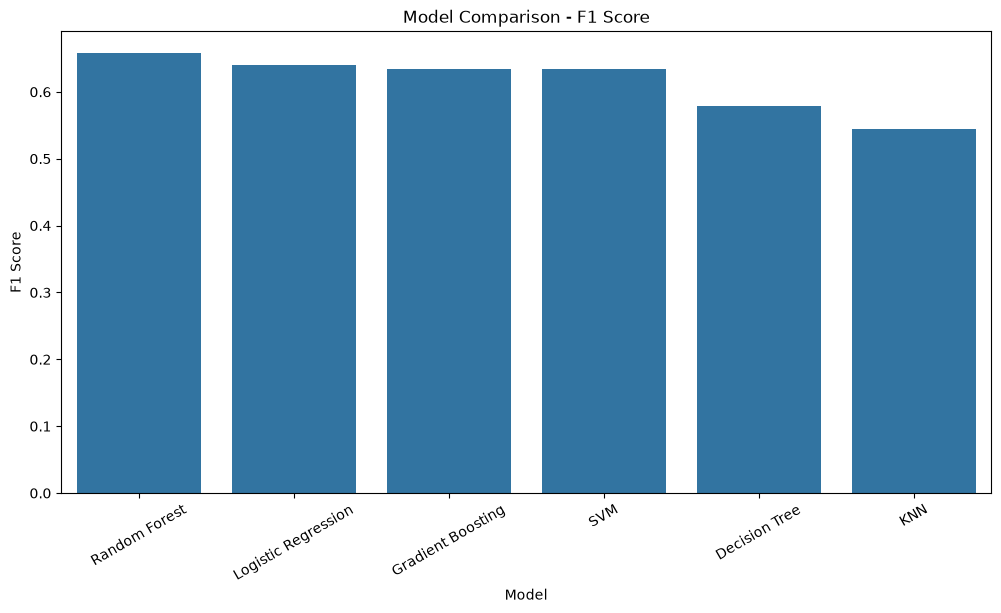

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.xticks(rotation=30)
plt.title("Model Comparison - F1 Score")
plt.ylabel("F1 Score")
plt.xlabel("Model")

plt.show()

In [12]:
best_model_name = results_df.iloc[0]["Model"]
best_f1 = results_df.iloc[0]["F1 Score"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", best_f1)

NameError: name 'results_df' is not defined

In [26]:
y_pred_best = best_model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred_best))

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92       934
           1       0.78      0.57      0.66       267

    accuracy                           0.87      1201
   macro avg       0.83      0.76      0.79      1201
weighted avg       0.86      0.87      0.86      1201



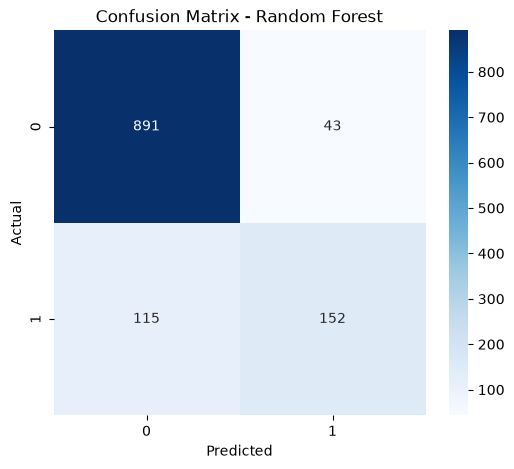

In [27]:
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [28]:
registered_model_name = "BankChurnBestModel"

# Get best model's MLflow run ID by searching the experiment
experiment = mlflow.get_experiment_by_name(
    "Bank_Churn_Prediction"
)

if experiment is None:
    # The earlier training runs were logged to the default experiment
    runs = mlflow.search_runs(
        order_by=["metrics.f1_score DESC"]
    )
else:
    runs = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        order_by=["metrics.f1_score DESC"]
    )

runs = runs[runs["metrics.f1_score"].notna()]

if runs.empty:
    raise ValueError("No MLflow runs with an f1_score metric were found.")

best_run_id = runs.iloc[0]["run_id"]

print("Best Model:", best_model_name)
print("Best Run ID:", best_run_id)

model_uri = f"runs:/{best_run_id}/model"

print("Model URI:", model_uri)

Best Model: Random Forest
Best Run ID: 4a90dab64e0d487ba6d14db6eafaf6d7
Model URI: runs:/4a90dab64e0d487ba6d14db6eafaf6d7/model


In [29]:
result_v1 = mlflow.register_model(
    model_uri=model_uri,
    name=registered_model_name
)

print("Registered Model:", registered_model_name)
print("Registered Version:", result_v1.version)

Successfully registered model 'BankChurnBestModel'.
2026/09/18 11:51:11 WARNING mlflow.tracking._model_registry.fluent: Run with id 4a90dab64e0d487ba6d14db6eafaf6d7 has no artifacts at artifact path 'model', registering model based on models:/m-0c6083ded6ba4e4887bb7065c498ec3e instead


Registered Model: BankChurnBestModel
Registered Version: 1


Created version '1' of model 'BankChurnBestModel'.


In [11]:
print("Best Model Type:", best_model_name)

if best_model_name == "Logistic Regression":
    model_v2 = LogisticRegression(
        C=0.5,
        max_iter=1500,
        random_state=RANDOM_STATE
    )

elif best_model_name == "Decision Tree":
    model_v2 = DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        random_state=RANDOM_STATE
    )

elif best_model_name == "Random Forest":
    model_v2 = RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=4,
        random_state=RANDOM_STATE
    )

elif best_model_name == "Gradient Boosting":
    model_v2 = GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        random_state=RANDOM_STATE
    )

elif best_model_name == "SVM":
    model_v2 = SVC(
        C=2.0,
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    )

elif best_model_name == "KNN":
    model_v2 = KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    )

pipeline_v2 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model_v2)
])

with mlflow.start_run(
    run_name=f"{best_model_name}_Version_2"
) as run:

    pipeline_v2.fit(X_train, y_train)

    y_pred_v2 = pipeline_v2.predict(X_test)
    y_prob_v2 = pipeline_v2.predict_proba(X_test)[:, 1]

    accuracy_v2 = accuracy_score(y_test, y_pred_v2)
    precision_v2 = precision_score(y_test, y_pred_v2, zero_division=0)
    recall_v2 = recall_score(y_test, y_pred_v2, zero_division=0)
    f1_v2 = f1_score(y_test, y_pred_v2, zero_division=0)
    roc_auc_v2 = roc_auc_score(y_test, y_prob_v2)

    mlflow.log_param("model_name", best_model_name)
    mlflow.log_param("version", "2")

    mlflow.log_metric("accuracy", accuracy_v2)
    mlflow.log_metric("precision", precision_v2)
    mlflow.log_metric("recall", recall_v2)
    mlflow.log_metric("f1_score", f1_v2)
    mlflow.log_metric("roc_auc", roc_auc_v2)

    mlflow.sklearn.log_model(
        pipeline_v2,
        name="model",
        skops_trusted_types=["numpy.dtype"]
    )

    model_uri_v2 = f"runs:/{run.info.run_id}/model"

print("Version 2 trained.")
print("F1 Score:", f1_v2)

NameError: name 'best_model_name' is not defined

In [31]:
result_v2 = mlflow.register_model(
    model_uri=model_uri_v2,
    name=registered_model_name
)

print("Registered Version:", result_v2.version)

Registered model 'BankChurnBestModel' already exists. Creating a new version of this model...
2026/09/18 11:51:46 WARNING mlflow.tracking._model_registry.fluent: Run with id 0cf54635068b456e9366785c31c59399 has no artifacts at artifact path 'model', registering model based on models:/m-84d146298f964f1c8264b71f76f7088a instead


Registered Version: 2


Created version '2' of model 'BankChurnBestModel'.


In [32]:
if best_model_name == "Logistic Regression":
    model_v3 = LogisticRegression(
        C=2.0,
        max_iter=2000,
        random_state=RANDOM_STATE
    )

elif best_model_name == "Decision Tree":
    model_v3 = DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=3,
        random_state=RANDOM_STATE
    )

elif best_model_name == "Random Forest":
    model_v3 = RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_split=2,
        random_state=RANDOM_STATE
    )

elif best_model_name == "Gradient Boosting":
    model_v3 = GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        random_state=RANDOM_STATE
    )

elif best_model_name == "SVM":
    model_v3 = SVC(
        C=5.0,
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    )

elif best_model_name == "KNN":
    model_v3 = KNeighborsClassifier(
        n_neighbors=9,
        weights="distance"
    )

pipeline_v3 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model_v3)
])

with mlflow.start_run(
    run_name=f"{best_model_name}_Version_3"
) as run:

    pipeline_v3.fit(X_train, y_train)

    y_pred_v3 = pipeline_v3.predict(X_test)
    y_prob_v3 = pipeline_v3.predict_proba(X_test)[:, 1]

    accuracy_v3 = accuracy_score(y_test, y_pred_v3)
    precision_v3 = precision_score(y_test, y_pred_v3, zero_division=0)
    recall_v3 = recall_score(y_test, y_pred_v3, zero_division=0)
    f1_v3 = f1_score(y_test, y_pred_v3, zero_division=0)
    roc_auc_v3 = roc_auc_score(y_test, y_prob_v3)

    mlflow.log_param("model_name", best_model_name)
    mlflow.log_param("version", "3")

    mlflow.log_metric("accuracy", accuracy_v3)
    mlflow.log_metric("precision", precision_v3)
    mlflow.log_metric("recall", recall_v3)
    mlflow.log_metric("f1_score", f1_v3)
    mlflow.log_metric("roc_auc", roc_auc_v3)

    mlflow.sklearn.log_model(
        pipeline_v3,
        name="model",
        skops_trusted_types=["numpy.dtype"]
    )

    model_uri_v3 = f"runs:/{run.info.run_id}/model"

print("Version 3 trained.")
print("F1 Score:", f1_v3)

Version 3 trained.
F1 Score: 0.6479481641468683


In [34]:
result_v3 = mlflow.register_model(
    model_uri=model_uri_v3,
    name=registered_model_name
)

print("Registered Version:", result_v3.version)

Registered model 'BankChurnBestModel' already exists. Creating a new version of this model...
2026/09/18 11:52:21 WARNING mlflow.tracking._model_registry.fluent: Run with id 138fd03c4c784711a2a414fd56a04cf1 has no artifacts at artifact path 'model', registering model based on models:/m-4283f95d30434fa9acadc3c66a34e145 instead


Registered Version: 4


Created version '4' of model 'BankChurnBestModel'.


In [35]:
version_results = pd.DataFrame({
    "Version": ["Version 1", "Version 2", "Version 3"],
    "Accuracy": [
        results_df.iloc[0]["Accuracy"],
        accuracy_v2,
        accuracy_v3
    ],
    "Precision": [
        results_df.iloc[0]["Precision"],
        precision_v2,
        precision_v3
    ],
    "Recall": [
        results_df.iloc[0]["Recall"],
        recall_v2,
        recall_v3
    ],
    "F1 Score": [
        results_df.iloc[0]["F1 Score"],
        f1_v2,
        f1_v3
    ],
    "ROC AUC": [
        results_df.iloc[0]["ROC AUC"],
        roc_auc_v2,
        roc_auc_v3
    ]
})

display(version_results)

,Version,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Version 1,0.868443,0.779487,0.569288,0.658009,0.896242
1,Version 2,0.869276,0.786458,0.565543,0.657952,0.897304
2,Version 3,0.864280,0.765306,0.561798,0.647948,0.897026


In [36]:
results_df.to_csv(
    "models/all_model_results.csv",
    index=False
)

version_results.to_csv(
    "models/model_version_results.csv",
    index=False
)

joblib.dump(
    best_model,
    "models/best_bank_churn_model.pkl"
)

print("Results and best model saved successfully.")

Results and best model saved successfully.


In [37]:
client = mlflow.MlflowClient()

registered_versions = client.search_model_versions(
    f"name='{registered_model_name}'"
)

for version in registered_versions:
    print(
        "Name:", version.name,
        "| Version:", version.version,
        "| Run ID:", version.run_id
    )

Name: BankChurnBestModel | Version: 4 | Run ID: 138fd03c4c784711a2a414fd56a04cf1
Name: BankChurnBestModel | Version: 3 | Run ID: 138fd03c4c784711a2a414fd56a04cf1
Name: BankChurnBestModel | Version: 2 | Run ID: 0cf54635068b456e9366785c31c59399
Name: BankChurnBestModel | Version: 1 | Run ID: 4a90dab64e0d487ba6d14db6eafaf6d7


In [38]:
# Set Version 2 as the champion model

client.set_registered_model_alias(
    name=registered_model_name,
    alias="champion",
    version="2"
)

print("Version 2 assigned as champion")

Version 2 assigned as champion


In [39]:
champion = client.get_model_version_by_alias(
    name=registered_model_name,
    alias="champion"
)

print("Champion Model :", champion.name)
print("Champion Version:", champion.version)
print("Champion Run ID :", champion.run_id)
print("Champion Alias  :", list(champion.aliases))

Champion Model : BankChurnBestModel
Champion Version: 2
Champion Run ID : 0cf54635068b456e9366785c31c59399
Champion Alias  : ['champion']


In [40]:
import mlflow.sklearn

MODEL_URI = f"models:/{registered_model_name}@champion"

loaded_model = mlflow.sklearn.load_model(MODEL_URI)

print("Champion model loaded successfully")
print("Model URI:", MODEL_URI)

Champion model loaded successfully
Model URI: models:/BankChurnBestModel@champion


In [41]:
print("Model Type:")
print(type(loaded_model))

print("\nLoaded Model:")
print(loaded_model)

Model Type:
<class 'sklearn.pipeline.Pipeline'>

Loaded Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['credit_score', 'age',
                                                   'tenure_years', 'balance',
                                                   'num_products',
                                                   'estimated_salary',
                                                   'monthly_transactions',
                                                   'complaints_last_year',
                                                   'balance_pe

In [42]:
sample = X_test.iloc[[0]]

print("Sample:")
display(sample)

prediction = loaded_model.predict(sample)

print("Prediction:", prediction)

Sample:


,credit_score,geography,gender,age,tenure_years,balance,num_products,has_cr_card,is_active_member,estimated_salary,monthly_transactions,complaints_last_year,balance_per_product,salary_to_balance_ratio,complaints_per_transaction,is_senior_customer,is_high_value_customer
3460,677.89053,france,female,47.839047,6,54485.065731,2,yes,yes,83455.217631,14,1,27242.532865,1.531708,0.071429,0,1


Prediction: [0]


In [43]:
api_sample = df.drop(
    columns=["customer_id", "churn"]
).iloc[0]

print(api_sample.to_json(indent=2))

{
  "credit_score":743.5200608678,
  "geography":"Germany",
  "gender":"female",
  "age":38.4608551327,
  "tenure_years":1,
  "balance":83722.026007423,
  "num_products":2,
  "has_cr_card":"no",
  "is_active_member":"no",
  "estimated_salary":29157.0836207381,
  "monthly_transactions":16,
  "complaints_last_year":0
}


In [44]:
%pip install fastapi uvicorn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [50]:
from typing import Any

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from fastapi import FastAPI, HTTPException


# =====================================================
# 1. MLflow Configuration
# =====================================================

MLFLOW_TRACKING_URI = "sqlite:///D:/kesava 2/231FA04B56/mlflow.db"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

print("MLflow Tracking URI:", mlflow.get_tracking_uri())


# =====================================================
# 2. Registered Champion Model
# =====================================================

MODEL_NAME = "BankChurnBestModel"

MODEL_URI = f"models:/{MODEL_NAME}@champion"


# =====================================================
# 3. Training Feature Engineering Configuration
# =====================================================

# This is the median used by the training dataset
BALANCE_MEDIAN = 42652.67939513792


# =====================================================
# 4. Feature Engineering
# =====================================================

def feature_engineering(data):

    data = data.copy()

    # ---------------------------------------------
    # Standardize categorical values
    # Same cleaning used during training
    # ---------------------------------------------

    data["gender"] = (
        data["gender"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    data["has_cr_card"] = (
        data["has_cr_card"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    data["is_active_member"] = (
        data["is_active_member"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # ---------------------------------------------
    # Feature 1: Balance per Product
    # ---------------------------------------------

    data["balance_per_product"] = (
        data["balance"] /
        data["num_products"].replace(0, np.nan)
    )

    # ---------------------------------------------
    # Feature 2: Salary to Balance Ratio
    # ---------------------------------------------

    data["salary_to_balance_ratio"] = (
        data["estimated_salary"] /
        data["balance"].replace(0, np.nan)
    )

    # ---------------------------------------------
    # Feature 3: Complaints per Transaction
    # ---------------------------------------------

    data["complaints_per_transaction"] = (
        data["complaints_last_year"] /
        data["monthly_transactions"].replace(0, np.nan)
    )

    # ---------------------------------------------
    # Feature 4: Senior Customer
    # ---------------------------------------------

    data["is_senior_customer"] = (
        data["age"] >= 50
    ).astype(int)

    # ---------------------------------------------
    # Feature 5: High Value Customer
    # ---------------------------------------------

    data["is_high_value_customer"] = (
        data["balance"] > BALANCE_MEDIAN
    ).astype(int)

    return data


# =====================================================
# 5. Load Champion Model
# =====================================================

try:

    model = mlflow.sklearn.load_model(MODEL_URI)

    model_loaded = True

    print("========================================")
    print("Model loaded successfully")
    print("Model Name:", MODEL_NAME)
    print("Model URI:", MODEL_URI)
    print("========================================")

except Exception as e:

    model = None

    model_loaded = False

    print("Model loading failed:", e)


# =====================================================
# 6. Create FastAPI Application
# =====================================================

app = FastAPI(
    title="Bank Churn Prediction API",
    description="REST API using the champion Bank Churn model registered in MLflow",
    version="1.0"
)


# =====================================================
# 7. Home Endpoint
# =====================================================

@app.get("/")
def home():

    return {
        "message": "Bank Churn Prediction API is running",
        "model": MODEL_NAME,
        "version": "champion"
    }


# =====================================================
# 8. Health Check Endpoint
# =====================================================

@app.get("/health")
def health():

    if model_loaded:

        return {
            "status": "healthy",
            "model_loaded": True,
            "model_name": MODEL_NAME,
            "model_uri": MODEL_URI
        }

    raise HTTPException(
        status_code=503,
        detail="Model is not available"
    )


# =====================================================
# 9. Features Endpoint
# =====================================================

@app.get("/features")
def features():

    return {

        "number_of_features": 12,

        "required_features": [

            "credit_score",

            "geography",

            "gender",

            "age",

            "tenure_years",

            "balance",

            "num_products",

            "has_cr_card",

            "is_active_member",

            "estimated_salary",

            "monthly_transactions",

            "complaints_last_year"

        ]
    }


# =====================================================
# 10. Prediction Endpoint
# =====================================================

@app.post("/predict")
def predict(data: dict[str, Any]):

    # ---------------------------------------------
    # Check Model
    # ---------------------------------------------

    if not model_loaded:

        raise HTTPException(
            status_code=503,
            detail="Model is not loaded"
        )


    # ---------------------------------------------
    # Required Input Features
    # ---------------------------------------------

    required_features = [

        "credit_score",

        "geography",

        "gender",

        "age",

        "tenure_years",

        "balance",

        "num_products",

        "has_cr_card",

        "is_active_member",

        "estimated_salary",

        "monthly_transactions",

        "complaints_last_year"

    ]


    # ---------------------------------------------
    # Check Missing Features
    # ---------------------------------------------

    missing_features = [

        feature

        for feature in required_features

        if feature not in data

    ]


    if missing_features:

        raise HTTPException(

            status_code=400,

            detail={

                "message": "Required features are missing",

                "missing_features": missing_features

            }

        )


    # ---------------------------------------------
    # Prediction
    # ---------------------------------------------

    try:

        # Create DataFrame
        input_df = pd.DataFrame([data])


        # Keep only expected input columns
        input_df = input_df[required_features]


        # Apply same feature engineering
        input_df = feature_engineering(input_df)


        # -----------------------------------------
        # Remove fields not used by model
        # -----------------------------------------

        if "customer_id" in input_df.columns:

            input_df = input_df.drop(
                columns=["customer_id"]
            )


        # -----------------------------------------
        # Model Prediction
        # -----------------------------------------

        prediction = model.predict(input_df)[0]


        # Convert NumPy value to Python value
        if hasattr(prediction, "item"):

            prediction = prediction.item()


        # -----------------------------------------
        # Prepare Result
        # -----------------------------------------

        result = {

            "prediction": prediction

        }


        # -----------------------------------------
        # Prediction Probabilities
        # -----------------------------------------

        if hasattr(model, "predict_proba"):

            probabilities = model.predict_proba(input_df)[0]

            result["probabilities"] = [

                float(value)

                for value in probabilities

            ]


        return result


    except Exception as e:

        raise HTTPException(

            status_code=500,

            detail=f"Prediction failed: {str(e)}"

        )

MLflow Tracking URI: sqlite:///D:/kesava 2/231FA04B56/mlflow.db
Model loading failed: Registered model alias champion not found.


In [51]:
%%writefile app.py

UsageError: %%writefile is a cell magic, but the cell body is empty.


In [46]:
import os

print("Current Folder:", os.getcwd())
print("app.py exists:", os.path.exists("app.py"))

Current Folder: d:\kesava 2\231FA04B56
app.py exists: True


In [47]:
import os

print(os.path.abspath("mlflow.db"))

d:\kesava 2\231FA04B56\mlflow.db


In [48]:
champion = client.get_model_version_by_alias(
    name=registered_model_name,
    alias="champion"
)

print("Champion Version:", champion.version)
print("Run ID:", champion.run_id)
print("Aliases:", list(champion.aliases))

Champion Version: 2
Run ID: 0cf54635068b456e9366785c31c59399
Aliases: ['champion']


In [49]:
import mlflow.sklearn

MODEL_URI = "models:/BankChurnBestModel@champion"

model = mlflow.sklearn.load_model(MODEL_URI)

print("Champion model loaded successfully!")
print("Model URI:", MODEL_URI)

Champion model loaded successfully!
Model URI: models:/BankChurnBestModel@champion


In [52]:
%%writefile app.py

from typing import Any

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from fastapi import FastAPI, HTTPException


# =====================================================
# MLflow Configuration
# =====================================================

MLFLOW_TRACKING_URI = "sqlite:///D:/kesava 2/231FA04B56/mlflow.db"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

print("MLflow Tracking URI:", mlflow.get_tracking_uri())


# =====================================================
# Registered Champion Model
# =====================================================

MODEL_NAME = "BankChurnBestModel"

MODEL_URI = f"models:/{MODEL_NAME}@champion"


# =====================================================
# Training Feature Engineering Configuration
# =====================================================

BALANCE_MEDIAN = 42652.67939513792


# =====================================================
# Feature Engineering
# =====================================================

def feature_engineering(data):

    data = data.copy()

    data["gender"] = (
        data["gender"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    data["has_cr_card"] = (
        data["has_cr_card"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    data["is_active_member"] = (
        data["is_active_member"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    data["balance_per_product"] = (
        data["balance"] /
        data["num_products"].replace(0, np.nan)
    )

    data["salary_to_balance_ratio"] = (
        data["estimated_salary"] /
        data["balance"].replace(0, np.nan)
    )

    data["complaints_per_transaction"] = (
        data["complaints_last_year"] /
        data["monthly_transactions"].replace(0, np.nan)
    )

    data["is_senior_customer"] = (
        data["age"] >= 50
    ).astype(int)

    data["is_high_value_customer"] = (
        data["balance"] > BALANCE_MEDIAN
    ).astype(int)

    return data


# =====================================================
# Load Champion Model
# =====================================================

try:

    model = mlflow.sklearn.load_model(MODEL_URI)

    model_loaded = True

    print("========================================")
    print("Model loaded successfully")
    print("Model Name:", MODEL_NAME)
    print("Model URI:", MODEL_URI)
    print("========================================")

except Exception as e:

    model = None

    model_loaded = False

    print("Model loading failed:", e)


# =====================================================
# FastAPI Application
# =====================================================

app = FastAPI(
    title="Bank Churn Prediction API",
    description="REST API using the champion Bank Churn model registered in MLflow",
    version="1.0"
)


# =====================================================
# Home Endpoint
# =====================================================

@app.get("/")
def home():

    return {
        "message": "Bank Churn Prediction API is running",
        "model": MODEL_NAME,
        "version": "champion"
    }


# =====================================================
# Health Check Endpoint
# =====================================================

@app.get("/health")
def health():

    if model_loaded:

        return {
            "status": "healthy",
            "model_loaded": True,
            "model_name": MODEL_NAME,
            "model_uri": MODEL_URI
        }

    raise HTTPException(
        status_code=503,
        detail="Model is not available"
    )


# =====================================================
# Features Endpoint
# =====================================================

@app.get("/features")
def features():

    return {
        "number_of_features": 12,
        "required_features": [
            "credit_score",
            "geography",
            "gender",
            "age",
            "tenure_years",
            "balance",
            "num_products",
            "has_cr_card",
            "is_active_member",
            "estimated_salary",
            "monthly_transactions",
            "complaints_last_year"
        ]
    }


# =====================================================
# Prediction Endpoint
# =====================================================

@app.post("/predict")
def predict(data: dict[str, Any]):

    if not model_loaded:

        raise HTTPException(
            status_code=503,
            detail="Model is not loaded"
        )

    required_features = [
        "credit_score",
        "geography",
        "gender",
        "age",
        "tenure_years",
        "balance",
        "num_products",
        "has_cr_card",
        "is_active_member",
        "estimated_salary",
        "monthly_transactions",
        "complaints_last_year"
    ]

    missing_features = [
        feature
        for feature in required_features
        if feature not in data
    ]

    if missing_features:

        raise HTTPException(
            status_code=400,
            detail={
                "message": "Required features are missing",
                "missing_features": missing_features
            }
        )

    try:

        input_df = pd.DataFrame([data])

        input_df = input_df[required_features]

        input_df = feature_engineering(input_df)

        prediction = model.predict(input_df)[0]

        if hasattr(prediction, "item"):
            prediction = prediction.item()

        result = {
            "prediction": prediction
        }

        if hasattr(model, "predict_proba"):

            probabilities = model.predict_proba(input_df)[0]

            result["probabilities"] = [
                float(value)
                for value in probabilities
            ]

        return result

    except Exception as e:

        raise HTTPException(
            status_code=500,
            detail=f"Prediction failed: {str(e)}"
        )

Writing app.py


In [2]:
import os

print("Current Folder:", os.getcwd())
print("app.py exists:", os.path.exists("app.py"))

Current Folder: d:\kesava 2\231FA04B56
app.py exists: True


In [3]:
api_sample = df.drop(
    columns=["customer_id", "churn"]
).iloc[0]

print(api_sample.to_json(indent=2))

NameError: name 'df' is not defined

In [4]:
import mlflow

mlflow.set_tracking_uri(
    "sqlite:///D:/kesava 2/231FA04B56/mlflow.db"
)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Artifact URI:", mlflow.get_artifact_uri())

2026/09/18 13:12:05 WARNING mlflow.tracking.fluent: No active run found. A new active run will be created. If this is not intended, please create a run using `mlflow.start_run()` first.


Tracking URI: sqlite:///D:/kesava 2/231FA04B56/mlflow.db
Artifact URI: file:///d:/4-1/MLops/231FA04B56/mlruns/0/b42bf90326d2485ca8ba0cb31e810e56/artifacts


In [5]:
import mlflow

if mlflow.active_run():
    mlflow.end_run()

In [6]:
import os

artifact_dir = r"D:\kesava 2\231FA04B56\mlruns"

os.makedirs(artifact_dir, exist_ok=True)

print(artifact_dir)

D:\kesava 2\231FA04B56\mlruns


In [7]:
import mlflow
import os

# Current project
PROJECT_DIR = r"D:\kesava 2\231FA04B56"

# MLflow database
mlflow.set_tracking_uri(
    "sqlite:///D:/kesava 2/231FA04B56/mlflow.db"
)

# Tell MLflow where new artifacts should be stored
mlflow.set_experiment("Bank_Churn_Prediction")

print("Tracking URI:", mlflow.get_tracking_uri())

2026/09/18 13:17:40 INFO mlflow.tracking.fluent: Experiment with name 'Bank_Churn_Prediction' does not exist. Creating a new experiment.


Tracking URI: sqlite:///D:/kesava 2/231FA04B56/mlflow.db


In [8]:
experiment = mlflow.get_experiment_by_name("Bank_Churn_Prediction")

print("Experiment ID:", experiment.experiment_id)
print("Artifact Location:", experiment.artifact_location)

Experiment ID: 1
Artifact Location: file:d:/kesava 2/231FA04B56/mlruns/1


In [9]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri(
    "sqlite:///D:/kesava 2/231FA04B56/mlflow.db"
)

mlflow.set_experiment("Bank_Churn_Prediction")

with mlflow.start_run(run_name="Bank_Churn_API_Model") as run:

    mlflow.sklearn.log_model(
        pipeline_v2,
        name="model",
        skops_trusted_types=["numpy.dtype"]
    )

    new_run_id = run.info.run_id

print("New Run ID:", new_run_id)
print("Artifact URI:", mlflow.get_artifact_uri())

NameError: name 'pipeline_v2' is not defined